# Regresión lineal

En este notebook vamos a ver cómo modelar datos mediante regresión lineal (multivariada) e interpretando los resultados.

Recomendamos el uso de la libreria de Python scikit-learn (https://scikit-learn.org/). Recomendamos hacer un pequeño "tour".

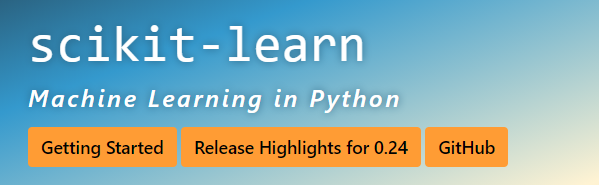


Scikit-learn no solamente es útil, sino que su documentación es excelente. Les recomendamos entrar a la página web y explorarla. Creemos que es posible aprender un montón de machine learning únicamente mirando la documentación de scikit-learn.

## Importamos las librerias

In [18]:
from sklearn import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [19]:
# cargamos un dataset que tiene scikitlearn
diabetes = datasets.load_diabetes()
X, y = diabetes.data, diabetes.target

Se obtuvieron diez variables basales, edad, sexo, índice de masa corporal, presión arterial promedio y seis mediciones del suero sanguíneo para cada uno de n = 442 pacientes con diabetes, así como la respuesta de interés, una medida cuantitativa de la progresión de la enfermedad un año después del inicio .

* age: age in years
* sex
* bmi: body mass index
* bp: average blood pressure
* s1: T-Cells (a type of white blood cells)
* s2: low-density lipoproteins
* s3: high-density lipoproteins
* s4: thyroid stimulating hormone
* s5: lamotrigine
* s6: blood sugar level

Objetivo: medida cuantitativa de la progresión de la enfermedad.

In [20]:
# veamos como se compone diabetes
diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]], shape=(442, 10)),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142.

In [21]:
# X es un array.
X

array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]], shape=(442, 10))

Si nos vemos en esta situación y queremos pasarlo a Dataframe para optar a sus funcionalidades, entonces haremos lo siguiente

In [22]:
df_x = pd.DataFrame(X)
df_x

,0,1,2,3,4,5,6,7,8,9
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [23]:
# con esto vemos los nombres de las variables
diabetes.feature_names

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

In [24]:
# agregamos los nombres de variables para una mejor visualización de los datos. Esto no es estrictamente necesario.
df_x.columns = diabetes.feature_names
df_x

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [25]:
# hacemos algo similar con la variable Y
df_y = pd.DataFrame(y)
df_y

,0
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


## Vamos a visualizar el comportamiento de 2 variables al mismo tiempo. Veremos varias combinaciones siempre dejando fija la variable Y

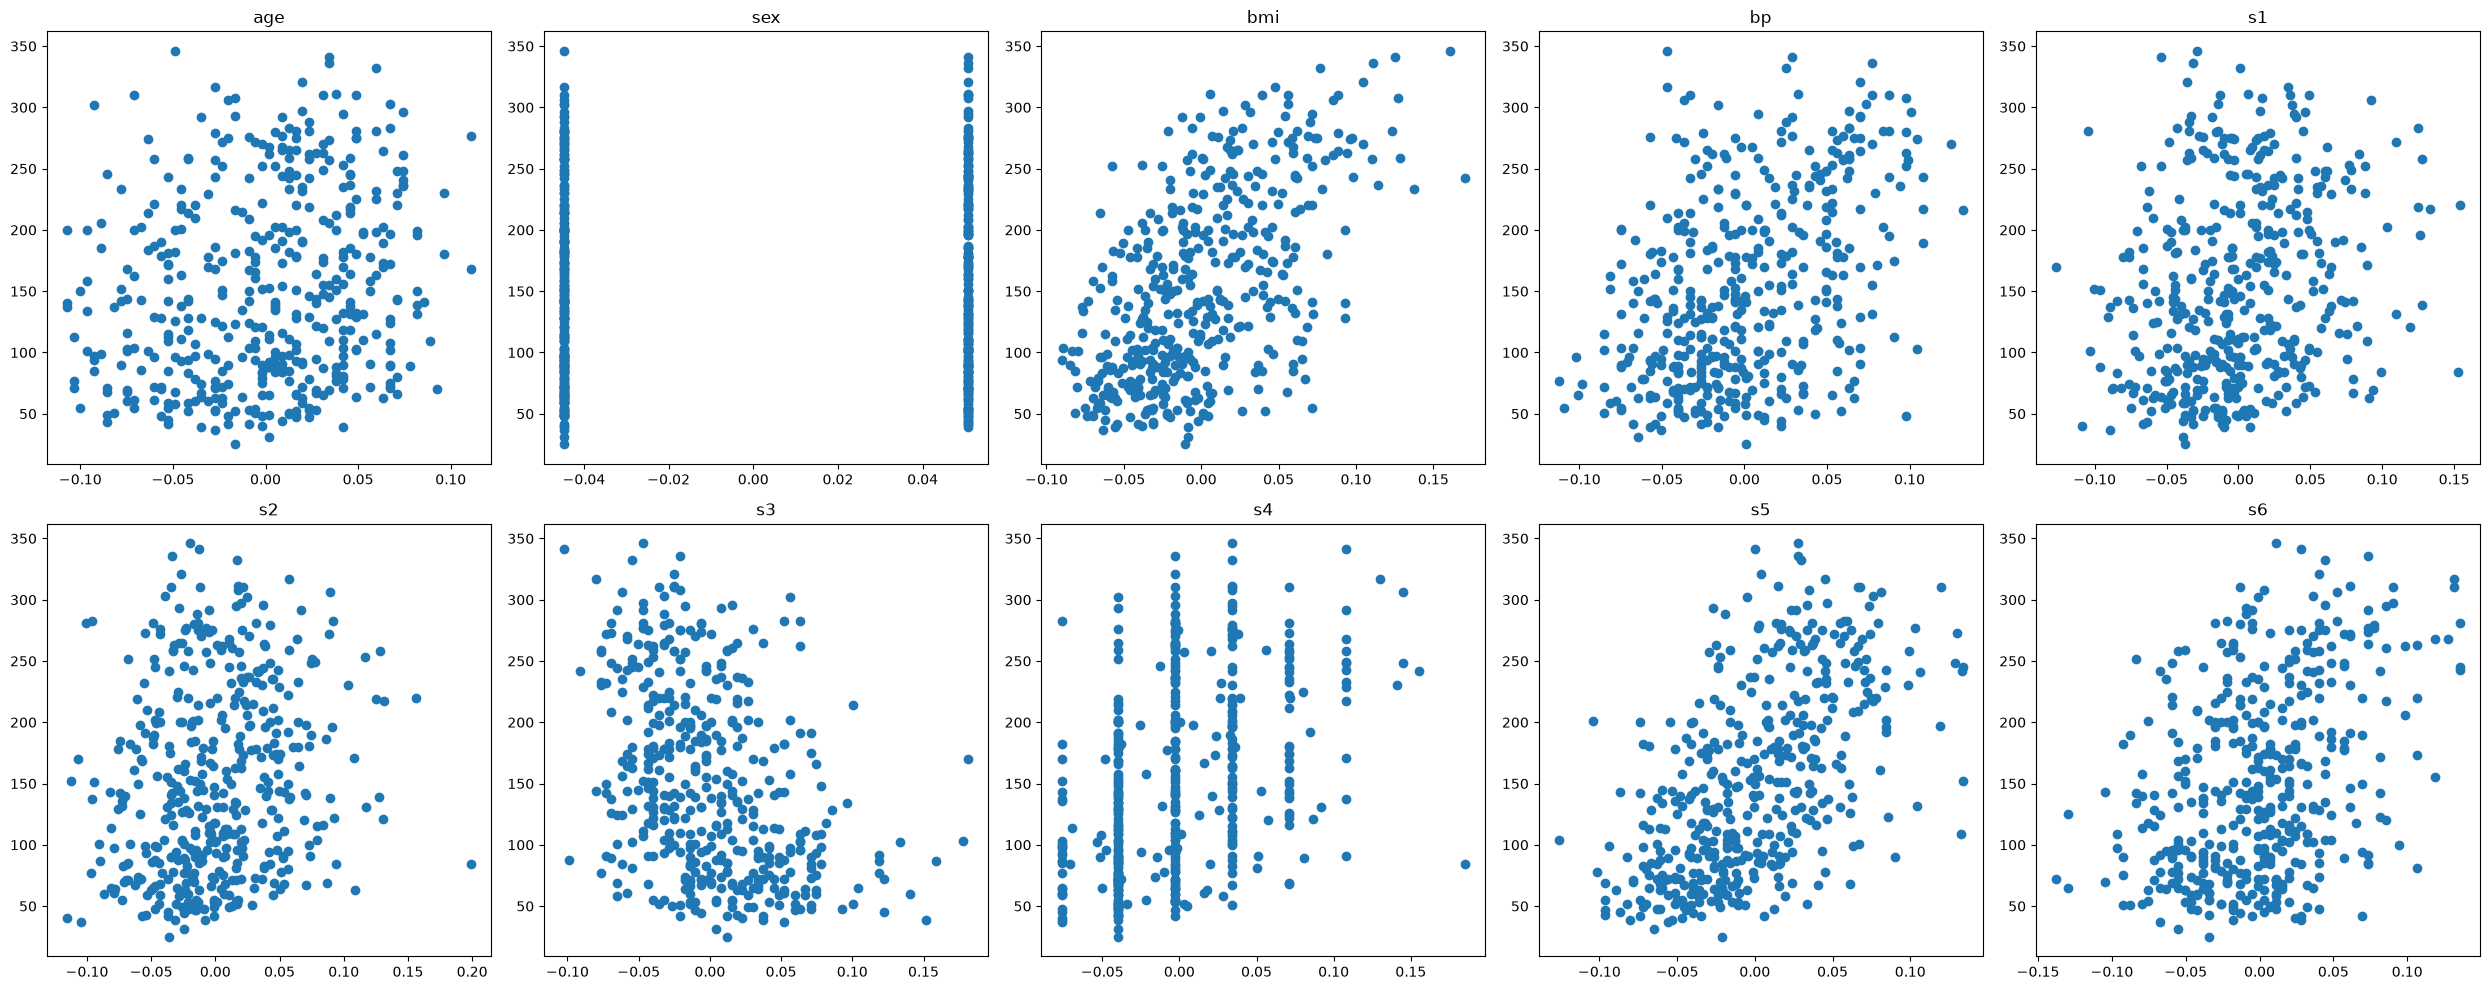

In [35]:
# Vemos la relación de cada variable con la variable Y

# Esto nos permite hacer un arreglo de gráficos. De 2 filas por 5 columnas
filas = 2
col = 5

nombres_col = diabetes.feature_names

# N es la cantidad de datos con los que trabajaremos. Se usa más adelante, atención!!
N = 441 # muestra la cantidad de puntos en el gráfico

fig, axs = plt.subplots(filas, col,figsize=(25,10))

n = 0
for i in range(0,2):
    for j in range(0,5):
        axs[i,j].set_title(nombres_col[n])
        axs[i,j].scatter(df_x[nombres_col[n]][:N],df_y[:N])
        n = n+1

fig.tight_layout()

## Probaremos como se ajustan los modelos

Debemos decidir cual variable usaremos para nuestra regresión Juegue probando varias

Coefficients: 
 Intercepto:  [152.28703762] 
Los demas parametros betas: [[694.20258936]]
Mean squared error: 4831.69
Mean absolute error: 57.72
Coefficient of determination: 0.18


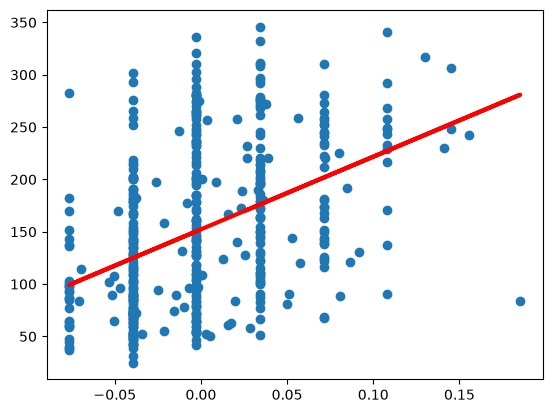

In [36]:
# definimos con cual variable trabajaremos. Debemos entregar el nombre de la variable
var = 's4'

# La función .reshape() permite cambiar la forma del vector. Se recomienda trabajar con arreglos al momento de realizar la regresión
X = np.array(df_x[var][:N]).reshape(-1,1)

# ******************** ACA SE REALIZA LA REGRESION **************************************

# Creamos el objeto de regresion lineal!!!!!
reg_lineal = linear_model.LinearRegression()

# Entrenamos el modelo!!!!!
reg_lineal.fit(X, df_y[:N])

# Hacemos predicciones!!!!
y_predicted = reg_lineal.predict(X) # hacemos predicciones de los mismos datos con los que entrenamos...OJO!!

# ******************** ACA SE TERMINA LA REGRESION **************************************


# Los coeficientes
print('Coefficients: \n', 'Intercepto: ',reg_lineal.intercept_, '\nLos demas parametros betas:',reg_lineal.coef_)

# ******************** ACA SE CALCULAN LAS METRICAS **************************************
# El mean squared error!!!!
print('Mean squared error: %.2f'
      % mean_squared_error(df_y[:N], y_predicted))

# El mean absolute error!!!!
print('Mean absolute error: %.2f'
      % mean_absolute_error(df_y[:N], y_predicted))

# El R2!!!!
print('Coefficient of determination: %.2f'
      % r2_score(df_y[:N], y_predicted))

# ******************** ACA SE TERMINA DE CALCULAR LAS METRICAS **************************************

# Graficamos
plt.scatter(X, df_y[:N])
plt.plot(X, y_predicted, color='red', linewidth=3)
plt.show()

## Como se habrá dado cuenta, la creación del modelo de regresión, el entrenamiento y la predicción de los datos es fácil. SOLO 3 LINEAS DE CODIGO.  Pero lo importante es preparar todo para llegar a ese punto. Luego, interpretar los datos es muy importante.

# ¿Qué puede decir del proceso?




Además, lo invitamos a ir probando variando los valores de N, la variable independiente, etc.

# ¿Predecir valores nuevos?

A continuación, un ejemplo:

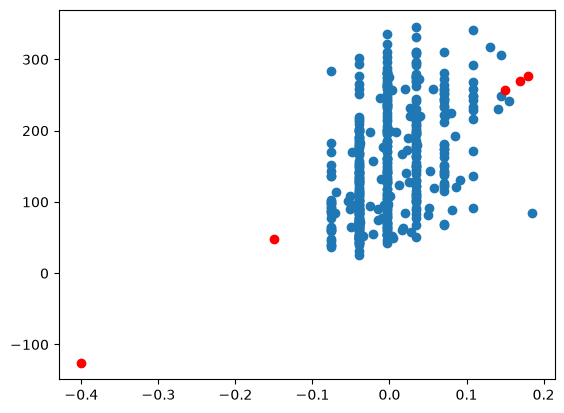

In [37]:
valores_nuevos = np.array([-0.40, -0.15, 0.15, 0.17, 0.18]) # puede probar otros valores y más si quiere.
X_nuevo = valores_nuevos.reshape(-1, 1)

y_nuevo = reg_lineal.predict(X_nuevo)  # hago la predicción para estos nuevos valores

plt.scatter(X,df_y[:N])
plt.scatter(X_nuevo,y_nuevo, color='r')


La predicción siempre será sobre la recta creada con los datos con los cuales fue entrenado el modelo.

# PREGUNTA: ¿QUE NOS FALTA HACER DE LO ESTUDIADO RECIENTEMENTE?

.







.












.








.







.





.





.


# Algo muy importante que debemos hacer es realizar la división de los datos originales en training set y testing set.

# **Esta será la forma de probar nuestros algoritmos. Lo anterior fue solo un primer ejemplo introductorio.**

Usaremos todos los datos del Dataframe, pero solo una variable independiente.

In [ ]:
# recordemos como son los datos         
df_x                                           

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [30]:
df_y

,0
0,151.0
1,75.0
2,141.0
3,206.0
4,135.0
...,...
437,178.0
438,104.0
439,132.0
440,220.0


In [39]:
# Importamos la función para dividir entre training set y testing set
from sklearn.model_selection import train_test_split

X = np.array(df_x['bmi']).reshape(-1,1) # al ser un solo vector, debemos aplicar .reshape()

# test_size es el tamaño del testing set.
# random_state es un valor que setea la aleatoriedad del método.
X_train, X_test, Y_train, Y_test = train_test_split(X, df_y, test_size=0.3, random_state=771)

In [40]:
# Creamos el objeto de regresion lineal!!!!!
reg_lineal = linear_model.LinearRegression()

# Entrenamos el modelo con los datos de entrenamiento
reg_lineal.fit(X_train, Y_train)

# Hacemos predicciones!!!!
y_predicted = reg_lineal.predict(X_test) # hacemos predicciones de los datos de test

# ******************** ACA SE TERMINA LA REGRESION **************************************


# Los coeficientes
print('Coefficients: \n', 'Intercepto: ',reg_lineal.intercept_, '\nLos demas parametros betas:',reg_lineal.coef_)

# ******************** ACA SE CALCULAN LAS METRICAS **************************************
# El mean squared error!!!!
print('Mean squared error: %.2f'
      % mean_squared_error(Y_test, y_predicted))

# El mean absolute error!!!!
print('Mean absolute error: %.2f'
      % mean_absolute_error(Y_test, y_predicted))

# El R2!!!!
print('Coefficient of determination: %.2f'
      % r2_score(Y_test, y_predicted))

Coefficients: 
 Intercepto:  [153.01250233] 
Los demas parametros betas: [[970.6731983]]
Mean squared error: 3932.47
Mean absolute error: 52.98
Coefficient of determination: 0.28


## Ahora lo hacemos con 3 variables independientes:

**Regresión multivariada o Regresión lineal multiple**

In [41]:
X = df_x[['bmi', 'bp', 's1']]

X_train, X_test, Y_train, Y_test = train_test_split(X, df_y, test_size=0.3, random_state=771)

In [42]:
# Creamos el objeto de regresion lineal!!!!!
reg_lineal = linear_model.LinearRegression()

# Entrenamos el modelo con los datos de entrenamiento
reg_lineal.fit(X_train, Y_train)

# Hacemos predicciones!!!!
y_predicted = reg_lineal.predict(X_test) # hacemos predicciones de los datos de test

# ******************** ACA SE TERMINA LA REGRESION **************************************


# Los coeficientes
print('Coefficients: \n', 'Intercepto: ',reg_lineal.intercept_, '\nLos demas parametros betas:',reg_lineal.coef_)

# ******************** ACA SE CALCULAN LAS METRICAS **************************************
# El mean squared error!!!!
print('Mean squared error: %.2f'
      % mean_squared_error(Y_test, y_predicted))

# El mean absolute error!!!!
print('Mean absolute error: %.2f'
      % mean_absolute_error(Y_test, y_predicted))

# El R2!!!!
print('Coefficient of determination: %.2f'
      % r2_score(Y_test, y_predicted))

Coefficients: 
 Intercepto:  [153.25857132] 
Los demas parametros betas: [[781.15858113 382.23452492 125.59136941]]
Mean squared error: 3710.39
Mean absolute error: 51.06
Coefficient of determination: 0.32


**¿Cómo interpreta los resultados?**

# ¿Puede mejorar el modelo? ¿En que debe fijarse?

# Intente mejorarlo.

## Análisis de correlación: Pearson y Spearman

Antes de elegir las variables para el modelo, conviene medir qué tan relacionada está cada variable independiente con la variable objetivo (`y`).

* **Pearson**: mide relación **lineal** entre dos variables (va de -1 a 1).
* **Spearman**: mide relación **monótona** (no necesariamente lineal), usando el orden (rangos) de los datos.

Si Pearson y Spearman son similares, la relación es aproximadamente lineal. Si Spearman es notoriamente mayor que Pearson, hay relación monótona pero no lineal.

In [ ]:
from scipy.stats import pearsonr, spearmanr

# nos aseguramos de tener y como un vector 1D (no como DataFrame de 1 columna)
y_vector = df_y.iloc[:, 0]

resultados = []

for col in df_x.columns:
    r_pearson, p_pearson = pearsonr(df_x[col], y_vector)
    r_spearman, p_spearman = spearmanr(df_x[col], y_vector)
    resultados.append({
        'variable': col,
        'pearson_r': r_pearson,
        'pearson_p_value': p_pearson,
        'spearman_r': r_spearman,
        'spearman_p_value': p_spearman
    })

df_corr = pd.DataFrame(resultados).sort_values(by='pearson_r', key=abs, ascending=False)
df_corr

In [ ]:
# Matriz de correlación completa (todas las variables entre sí, incluyendo y)
# Esto permite ver no solo la relación de cada variable con y, sino también
# relaciones entre las propias variables independientes (multicolinealidad).
#
# Pearson: relación lineal.
# Spearman: relación monótona (basada en rangos).
# Kendall: también basada en rangos, pero mide concordancia de pares (tau).
#          Suele ser más robusta a outliers y datos pequeños que Spearman.

df_completo = df_x.copy()
df_completo['y'] = y_vector

matriz_pearson = df_completo.corr(method='pearson')
matriz_spearman = df_completo.corr(method='spearman')
matriz_kendall = df_completo.corr(method='kendall')

fig, axs = plt.subplots(1, 3, figsize=(22, 7))

for ax, matriz, titulo in zip(axs, [matriz_pearson, matriz_spearman, matriz_kendall], ['Pearson', 'Spearman', 'Kendall']):
    im = ax.imshow(matriz.values, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set_xticks(range(len(matriz.columns)))
    ax.set_xticklabels(matriz.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(matriz.index)))
    ax.set_yticklabels(matriz.index)
    ax.set_title(f'Matriz de correlación de {titulo}')
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            ax.text(j, i, f'{matriz.values[i, j]:.2f}', ha='center', va='center',
                     color='white' if abs(matriz.values[i, j]) > 0.6 else 'black', fontsize=8)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

fig.tight_layout()
plt.show()

In [ ]:
# Buscamos las relaciones (pares de variables) más fuertes, sin contar la diagonal

def top_correlaciones(matriz, n=10):
    pares = matriz.where(~np.eye(matriz.shape[0], dtype=bool)).stack()
    pares = pares[~pares.index.duplicated()]  # evita duplicar (a,b) y (b,a)
    # nos quedamos solo con un lado del par
    vistos = set()
    filas = []
    for (a, b), valor in pares.items():
        clave = frozenset((a, b))
        if clave in vistos:
            continue
        vistos.add(clave)
        filas.append({'variable_1': a, 'variable_2': b, 'correlacion': valor})
    df_pares = pd.DataFrame(filas).sort_values(by='correlacion', key=abs, ascending=False)
    return df_pares.head(n)

print('Top relaciones según Pearson (lineales):')
display(top_correlaciones(matriz_pearson))

print('
Top relaciones según Spearman (monótonas):')
display(top_correlaciones(matriz_spearman))

print('
Top relaciones según Kendall (concordancia de pares):')
display(top_correlaciones(matriz_kendall))

## ¿Qué matriz de correlación aplica mejor en este caso?

**Pearson** es la que más aplica acá, por varias razones:

1. **El modelo usado es regresión lineal.** `LinearRegression()` asume relaciones lineales entre `X` e `y`, y Pearson mide exactamente eso (correlación lineal). Si una variable tiene Pearson alto, es candidata directa a explicar bien el modelo.
2. **Las variables son continuas y ya vienen estandarizadas** (media 0, sin outliers extremos). Pearson funciona mejor en ese escenario. Spearman y Kendall están pensados para outliers fuertes, relaciones no lineales pero monótonas, o datos ordinales/con muchos empates, que no es el caso acá.
3. **Spearman y Kendall no aportan mucho extra**: al comparar `matriz_pearson` con `matriz_spearman` y `matriz_kendall`, los valores salen parecidos entre sí, lo que indica que las relaciones ya son aproximadamente lineales (Pearson ya captura lo importante).

**Conclusión práctica:** usar **Pearson** como criterio principal para elegir variables para la regresión lineal (`bmi`, `s5`, `bp` suelen salir con mayor `|pearson_r|`), y dejar Spearman/Kendall solo como respaldo para confirmar que no hay una relación no lineal escondida detrás.

*Se usaría Spearman/Kendall en cambio si el scatter mostrara una relación curva pero creciente, o si hubiera outliers fuertes distorsionando Pearson.*